# ПР №7 — Случайный лес, уровень B

Используется **тот же датасет, что в ПР-5** (`Breast Cancer Wisconsin`), чтобы сравнение было последовательным. В методичке этот датасет требуется согласовать с преподавателем. Положительный класс = malignant.

In [1]:
from pathlib import Path
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split,GridSearchCV,cross_val_score,StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,f1_score,roc_auc_score
FIG=Path('../figures');FIG.mkdir(exist_ok=True)
df=pd.read_csv('../data/breast_cancer.csv')
X=df.drop(columns='malignant');y=df['malignant']
Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=.2,random_state=42,stratify=y)
cv=StratifiedKFold(n_splits=3,shuffle=True,random_state=42)
print('Train/test:',Xtr.shape,Xte.shape)

Train/test: (455, 30) (114, 30)


## Одиночное дерево, случайный лес по умолчанию и настроенный лес

Гиперпараметры `n_estimators`, `max_depth`, `min_samples_leaf` перебираем с кросс-валидацией на **train**. Оптимизируем F1; test оставляем для финальной оценки.

In [2]:
tree=DecisionTreeClassifier(random_state=42)
forest_default=RandomForestClassifier(random_state=42,n_jobs=1)
search=GridSearchCV(RandomForestClassifier(random_state=42,n_jobs=1),param_grid={'n_estimators':[60,120],'max_depth':[None,5,10],'min_samples_leaf':[1,3]},scoring='f1',cv=cv,n_jobs=1)
search.fit(Xtr,ytr)
forest=search.best_estimator_
tree.fit(Xtr,ytr);forest_default.fit(Xtr,ytr)
print('Выбранные параметры:',search.best_params_)
print('CV F1 лучшего варианта:',round(search.best_score_,3))
rows=[]
for name,model in [('DecisionTree',tree),('RandomForest default',forest_default),('RandomForest tuned',forest)]:
    pred=model.predict(Xte);probs=model.predict_proba(Xte)[:,1]
    rows.append({'model':name,'accuracy':accuracy_score(yte,pred),'F1':f1_score(yte,pred),'ROC_AUC':roc_auc_score(yte,probs)})
results=pd.DataFrame(rows);display(results.round(3))
print('Число деревьев tuned:',forest.n_estimators,'(выбрано по максимальному F1 на CV).')

Выбранные параметры: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 60}
CV F1 лучшего варианта: 0.953


,model,accuracy,F1,ROC_AUC
0,DecisionTree,0.930,0.905,0.925
1,RandomForest default,0.974,0.963,0.993
2,RandomForest tuned,0.965,0.950,0.994


Число деревьев tuned: 60 (выбрано по максимальному F1 на CV).


## Важность признаков

Встроенная важность измеряет уменьшение неоднородности (impurity). Это **не причинно-следственная связь**, а коррелирующие признаки могут делить важность между собой.

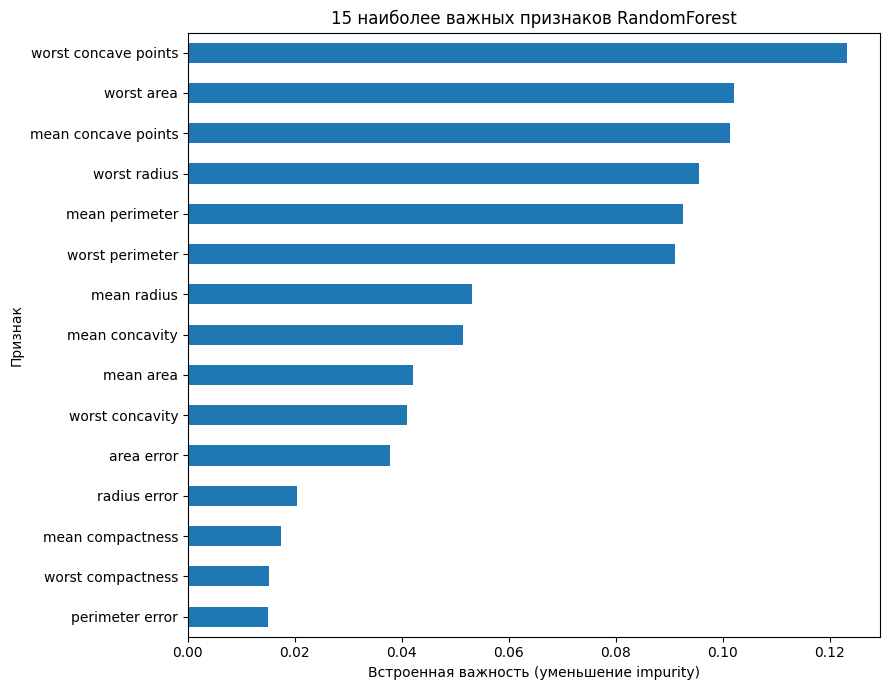

,importance
worst concave points,0.123246
worst area,0.102061
mean concave points,0.101390
worst radius,0.095601
mean perimeter,0.092617
worst perimeter,0.091108
mean radius,0.053106
mean concavity,0.051520
mean area,0.042159
worst concavity,0.041048


In [3]:
importance=pd.Series(forest.feature_importances_,index=Xtr.columns).sort_values(ascending=False)
fig,ax=plt.subplots(figsize=(9,7));importance.head(15).sort_values().plot.barh(ax=ax)
ax.set(title='15 наиболее важных признаков RandomForest',xlabel='Встроенная важность (уменьшение impurity)',ylabel='Признак')
fig.tight_layout();fig.savefig(FIG/'feature_importance.png',dpi=125);plt.show()
display(importance.head(10).rename('importance').to_frame())

## Можно ли убрать слабые признаки?

Проверяем варианты `все`, `минус 5`, `минус 10` на **кросс-валидации обучающей части** с одинаковыми параметрами леса. Фиксируем рейтинг важности по train (это приблизительный эксперимент; для строгой оценки отбора признаков нужен вложенный CV). Тест нужен только для проверки выбранного количества.

,n_features,cv_f1_mean,cv_f1_std
0,30,0.934,0.025
1,25,0.938,0.022
2,20,0.940,0.012


Выбрано признаков по CV: 20 из 30
Удалены: ['compactness error', 'concavity error', 'texture error', 'mean smoothness', 'symmetry error', 'mean fractal dimension', 'worst fractal dimension', 'mean symmetry', 'smoothness error', 'concave points error']
Финальный F1 на test: 0.963


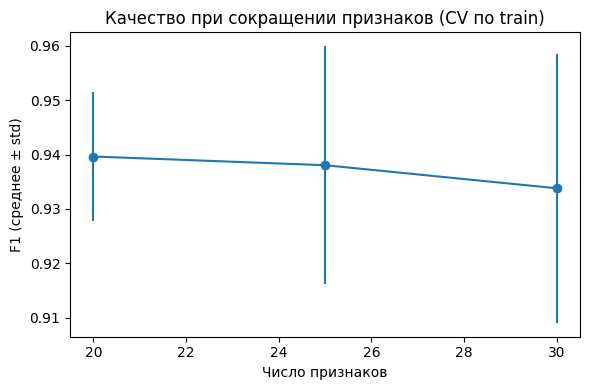

In [4]:
sizes=[len(importance),len(importance)-5,len(importance)-10]
rows=[]
for k in sizes:
    features=importance.index[:k].tolist()
    candidate=RandomForestClassifier(**search.best_params_,random_state=42,n_jobs=1)
    scores=cross_val_score(candidate,Xtr[features],ytr,scoring='f1',cv=cv,n_jobs=1)
    rows.append({'n_features':k,'cv_f1_mean':scores.mean(),'cv_f1_std':scores.std()})
selection=pd.DataFrame(rows);display(selection.round(3))
# Максимальное ухудшение CV F1 на <= 0.01 по отношению ко всем признакам считаем допустимым.
base_cv=float(selection.iloc[0].cv_f1_mean)
acceptable=selection[selection.cv_f1_mean>=base_cv-.01]
selected_n=int(acceptable.sort_values('n_features').iloc[0].n_features)
selected_features=importance.index[:selected_n].tolist()
final=RandomForestClassifier(**search.best_params_,random_state=42,n_jobs=1).fit(Xtr[selected_features],ytr)
final_pred=final.predict(Xte[selected_features])
print('Выбрано признаков по CV:',selected_n,'из',len(importance))
print('Удалены:',list(importance.index[selected_n:]))
print('Финальный F1 на test:',round(f1_score(yte,final_pred),3))
fig,ax=plt.subplots(figsize=(6,4));ax.errorbar(selection.n_features,selection.cv_f1_mean,yerr=selection.cv_f1_std,fmt='o-')
ax.set(title='Качество при сокращении признаков (CV по train)',xlabel='Число признаков',ylabel='F1 (среднее ± std)')
fig.tight_layout();fig.savefig(FIG/'feature_selection.png',dpi=130);plt.show()
Path('../reports').mkdir(exist_ok=True)
results.to_csv('../reports/models.csv',index=False);selection.to_csv('../reports/selection.csv',index=False)

## Вывод

In [5]:
drop=len(importance)-selected_n
print(f'В учебном эксперименте можно исключить {drop} слабых признаков по критерию ухудшения среднего CV F1 не более 0.01.')
print(f'RandomForest настроен на {forest.n_estimators} деревьев, max_depth={forest.max_depth}, min_samples_leaf={forest.min_samples_leaf}.')
print('Разница качества обусловлена данными и способом разбиения; результаты не означают, что признаки неважны причинно.')
print('Датасет для сдачи должен быть согласован с преподавателем.')

В учебном эксперименте можно исключить 10 слабых признаков по критерию ухудшения среднего CV F1 не более 0.01.
RandomForest настроен на 60 деревьев, max_depth=None, min_samples_leaf=1.
Разница качества обусловлена данными и способом разбиения; результаты не означают, что признаки неважны причинно.
Датасет для сдачи должен быть согласован с преподавателем.
